In [1]:
import os, random, time, json, math, copy
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

WORK_DIR = "/kaggle/working"
CKPT_DIR = os.path.join(WORK_DIR, "checkpoints")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Ready.")

Device: cuda | GPU: Tesla T4
Ready.


In [2]:
!pip install -q timm==1.0.9 torchmetrics==1.4.1 opencv-python-headless scikit-learn albumentations requests openpyxl thop --no-warn-script-location
print("Libraries installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 915.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.2/866.2 kB 38.3 MB/s eta 0:00:00
Libraries installed.


In [3]:
import cv2
import requests
import pandas as pd
from collections import Counter

# ---- Correct paths based on actual structure (this notebook) ----
PCOS_XAI_DIR         = "/kaggle/input/datasets/ibadeus/pcos-xai-ultrasound-dataset"
PCOSGEN_TRAIN_IMAGES = "/kaggle/input/datasets/arunthathid/gentrain/PCOSGen-train/images"
PCOSGEN_TRAIN_LABELS = "/kaggle/input/datasets/arunthathid/gentrain/PCOSGen-train/class_label.xlsx"
PCOSGEN_TEST_IMAGES  = "/kaggle/input/datasets/arunthathid/gentest/images"
TEST_LABELS_PATH     = "/kaggle/working/test_class_label.csv"

# ---- PCOS-XAI: folder-based labels ----
def list_from_folders(root, class_map):
    samples = []
    for dirpath, _, files in os.walk(root):
        label = class_map.get(os.path.basename(dirpath), None)
        if label is None:
            continue
        for fname in files:
            if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                samples.append((os.path.join(dirpath, fname), label))
    return samples

xai_samples = list_from_folders(PCOS_XAI_DIR, {"infected": 1, "noninfected": 0})
print(f"PCOS-XAI raw: {len(xai_samples)}")
def load_from_label_file(label_path, images_dir):
    df = pd.read_csv(label_path) if label_path.endswith(".csv") else pd.read_excel(label_path)
    samples, missing = [], 0
    for _, row in df.iterrows():
        img_path = os.path.join(images_dir, row["imagePath"])
        if os.path.exists(img_path):
            samples.append((img_path, 0 if row["Healthy"] == 1 else 1))
        else:
            missing += 1
    print(f"  {os.path.basename(label_path)}: {len(samples)} loaded, {missing} missing")
    return samples

# fetch test labels CSV if not already present
if not os.path.exists(TEST_LABELS_PATH):
    print("Fetching PCOSGen test labels from Zenodo...")
    r = requests.get("https://zenodo.org/records/10960327/files/class%20label.csv?download=1", timeout=60)
    r.raise_for_status()
    with open(TEST_LABELS_PATH, "wb") as f:
        f.write(r.content)
    print("Done.")

pcosgen_train   = load_from_label_file(PCOSGEN_TRAIN_LABELS, PCOSGEN_TRAIN_IMAGES)
pcosgen_test    = load_from_label_file(TEST_LABELS_PATH, PCOSGEN_TEST_IMAGES)
pcosgen_samples = pcosgen_train + pcosgen_test

print(f"PCOSGen raw: {len(pcosgen_samples)}")
print(f"Total raw: {len(xai_samples) + len(pcosgen_samples)}")
print("PCOS-XAI distribution:", Counter([s[1] for s in xai_samples]))
print("PCOSGen distribution:", Counter([s[1] for s in pcosgen_samples]))

PCOS-XAI raw: 11784
Fetching PCOSGen test labels from Zenodo...
Done.
  class_label.xlsx: 3200 loaded, 0 missing
  test_class_label.csv: 1468 loaded, 0 missing
PCOSGen raw: 4668
Total raw: 16452
PCOS-XAI distribution: Counter({1: 6784, 0: 5000})
PCOSGen distribution: Counter({1: 3348, 0: 1320})


In [4]:
import hashlib

def md5_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Deduplicating PCOS-XAI...")
seen_md5 = set()
dedup_xai = []
for path, label in xai_samples:
    h = md5_hash(path)
    if h not in seen_md5:
        seen_md5.add(h)
        dedup_xai.append((path, label))
print(f"  PCOS-XAI: {len(xai_samples)} -> {len(dedup_xai)} unique")

print("Deduplicating PCOSGen (also removing cross-dataset duplicates)...")
dedup_pcosgen = []
for path, label in pcosgen_samples:
    h = md5_hash(path)
    if h not in seen_md5:
        seen_md5.add(h)
        dedup_pcosgen.append((path, label))
print(f"  PCOSGen: {len(pcosgen_samples)} -> {len(dedup_pcosgen)} unique")

dedup_xai_tagged     = [(p, l, 0) for p, l in dedup_xai]
dedup_pcosgen_tagged = [(p, l, 1) for p, l in dedup_pcosgen]
all_samples = dedup_xai_tagged + dedup_pcosgen_tagged

print(f"\nCombined unique samples: {len(all_samples)}")
print("Class distribution:", Counter([s[1] for s in all_samples]))
print("Source distribution (0=XAI, 1=PCOSGen):", Counter([s[2] for s in all_samples]))

Deduplicating PCOS-XAI...
  PCOS-XAI: 11784 -> 3996 unique
Deduplicating PCOSGen (also removing cross-dataset duplicates)...
  PCOSGen: 4668 -> 2295 unique

Combined unique samples: 6291
Class distribution: Counter({1: 4202, 0: 2089})
Source distribution (0=XAI, 1=PCOSGen): Counter({0: 3996, 1: 2295})


In [5]:
def apply_clahe(img, clip_limit=2.0, tile_grid_size=(8, 8)):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    enhanced = clahe.apply(gray)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

def load_and_preprocess(path, img_size=224):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    img = apply_clahe(img)
    return cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)

test_img = load_and_preprocess(all_samples[0][0])
print("Sample shape:", test_img.shape, "dtype:", test_img.dtype)

Sample shape: (224, 224, 3) dtype: uint8


In [6]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.2),
    A.ElasticTransform(alpha=1, sigma=20, p=0.15),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
eval_transform = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
print("Augmentation pipelines ready.")

Augmentation pipelines ready.


In [7]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

class PCOSDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label, source = self.samples[idx]
        img = load_and_preprocess(path)
        if self.transform:
            img = self.transform(image=img)["image"]
        return img, torch.tensor(label, dtype=torch.long), torch.tensor(source, dtype=torch.long)

labels_all = [s[1] for s in all_samples]
train_val, test = train_test_split(all_samples, test_size=0.2, stratify=labels_all, random_state=SEED)
train, val = train_test_split(train_val, test_size=0.125,
                               stratify=[s[1] for s in train_val], random_state=SEED)

print(f"Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")

BATCH_SIZE = 16
train_loader = DataLoader(PCOSDataset(train, train_transform), batch_size=BATCH_SIZE,
                           shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(PCOSDataset(val, eval_transform), batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(PCOSDataset(test, eval_transform), batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)

train_labels = [s[1] for s in train]
class_counts = Counter(train_labels)
w_neg = len(train) / (2 * class_counts[0])
w_pos = len(train) / (2 * class_counts[1])
class_weights = torch.tensor([w_neg, w_pos], dtype=torch.float).to(DEVICE)
ce_loss_fn = nn.CrossEntropyLoss(weight=class_weights)
print(f"Class weights: negative={w_neg:.3f}, positive={w_pos:.3f}")

Train: 4403 | Val: 629 | Test: 1259
Class weights: negative=1.506, positive=0.749


In [8]:
import timm
import torch.optim as optim
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, matthews_corrcoef, confusion_matrix,
                              roc_curve, auc)

In [9]:
class AdaptiveCrossAttention(nn.Module):
    def __init__(self, dim=256, num_heads=8, dropout=0.1):
        super().__init__()
        self.dim = dim
        self.cnn_to_vit = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.vit_to_cnn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm_cnn = nn.LayerNorm(dim)
        self.norm_vit = nn.LayerNorm(dim)
        self.gate = nn.Sequential(nn.Linear(dim*2, dim//2), nn.ReLU(inplace=True),
                                   nn.Linear(dim//2, 2), nn.Softmax(dim=-1))
    @staticmethod
    def _flatten(feat_map):
        B, C, H, W = feat_map.shape
        return feat_map.flatten(2).transpose(1, 2), (H, W)
    def forward(self, cnn_feat, vit_feat):
        if cnn_feat.shape[-2:] != vit_feat.shape[-2:]:
            vit_feat = nn.functional.interpolate(vit_feat, size=cnn_feat.shape[-2:],
                                                  mode="bilinear", align_corners=False)
        cnn_tok, (H, W) = self._flatten(cnn_feat)
        vit_tok, _ = self._flatten(vit_feat)
        cnn_attended, _ = self.cnn_to_vit(cnn_tok, vit_tok, vit_tok)
        vit_attended, _ = self.vit_to_cnn(vit_tok, cnn_tok, cnn_tok)
        cnn_out = self.norm_cnn(cnn_tok + cnn_attended)
        vit_out = self.norm_vit(vit_tok + vit_attended)
        weights = self.gate(torch.cat([cnn_out.mean(1), vit_out.mean(1)], dim=-1))
        w_cnn, w_vit = weights[:, 0:1, None], weights[:, 1:2, None]
        fused = (w_cnn * cnn_out + w_vit * vit_out).transpose(1, 2).reshape(-1, self.dim, H, W)
        return fused, weights

def coral_loss(source_feats, target_feats):
    d = source_feats.size(1)
    src = source_feats - source_feats.mean(dim=0, keepdim=True)
    tgt = target_feats - target_feats.mean(dim=0, keepdim=True)
    cov_src = (src.t() @ src) / (src.size(0) - 1 + 1e-6)
    cov_tgt = (tgt.t() @ tgt) / (tgt.size(0) - 1 + 1e-6)
    return torch.sum((cov_src - cov_tgt) ** 2) / (4 * d * d)

print("Cross-attention and CORAL loss defined.")

Cross-attention and CORAL loss defined.


In [10]:
class RepViTM2Extractor(nn.Module):
    def __init__(self, pretrained=True, out_dim=256):
        super().__init__()
        self.backbone = timm.create_model("repvit_m2", pretrained=pretrained, num_classes=0, global_pool="")
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feat = self.backbone.forward_features(dummy)
        feat_ch = feat.shape[1]
        self.proj = nn.Conv2d(feat_ch, out_dim, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_dim)
        self.act = nn.SiLU(inplace=True)
    def forward(self, x):
        feat = self.backbone.forward_features(x)
        return self.act(self.bn(self.proj(feat)))

class EfficientViTB2Extractor(nn.Module):
    def __init__(self, pretrained=True, out_dim=256):
        super().__init__()
        # NOTE: EfficientViT-B2's head requires pooling enabled at construction time,
        # so we build with default pooling but only ever call forward_features(),
        # which returns the pre-head spatial feature map regardless of head config.
        self.backbone = timm.create_model("efficientvit_b2", pretrained=pretrained, num_classes=0)
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feat = self.backbone.forward_features(dummy)
        feat_ch = feat.shape[1]
        self.proj = nn.Conv2d(feat_ch, out_dim, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_dim)
        self.act = nn.SiLU(inplace=True)
    def forward(self, x):
        feat = self.backbone.forward_features(x)
        return self.act(self.bn(self.proj(feat)))

_rep_test = RepViTM2Extractor(pretrained=True).to(DEVICE)
_evit_test = EfficientViTB2Extractor(pretrained=True).to(DEVICE)
_sample, _, _ = next(iter(train_loader))
with torch.no_grad():
    _rep_out = _rep_test(_sample.to(DEVICE))
    _evit_out = _evit_test(_sample.to(DEVICE))
print("RepViT-M2 feature map shape:", _rep_out.shape)
print("EfficientViT-B2 feature map shape:", _evit_out.shape)
del _rep_test, _evit_test, _rep_out, _evit_out
torch.cuda.empty_cache()

model.safetensors:   0%|          | 0.00/35.5M [00:00<?, ?B/s]

Unexpected keys (head.head.bn.num_batches_tracked, head.head.bn.bias, head.head.bn.running_mean, head.head.bn.running_var, head.head.bn.weight, head.head_dist.bn.num_batches_tracked, head.head_dist.bn.bias, head.head_dist.bn.running_mean, head.head_dist.bn.running_var, head.head_dist.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


model.safetensors:   0%|          | 0.00/97.5M [00:00<?, ?B/s]

RepViT-M2 feature map shape: torch.Size([16, 256, 7, 7])
EfficientViT-B2 feature map shape: torch.Size([16, 256, 7, 7])


In [11]:
class RepFormerPCOS(nn.Module):
    def __init__(self, fusion_dim=256, num_classes=2, pretrained=True):
        super().__init__()
        self.rep_branch = RepViTM2Extractor(pretrained=pretrained, out_dim=fusion_dim)
        self.evit_branch = EfficientViTB2Extractor(pretrained=pretrained, out_dim=fusion_dim)
        self.cross_attn = AdaptiveCrossAttention(dim=fusion_dim, num_heads=8)
        self.dw_conv = nn.Sequential(
            nn.Conv2d(fusion_dim, fusion_dim, kernel_size=3, padding=1, groups=fusion_dim, bias=False),
            nn.BatchNorm2d(fusion_dim), nn.SiLU(inplace=True))
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, fusion_dim // 2), nn.ReLU(inplace=True),
            nn.Dropout(0.3), nn.Linear(fusion_dim // 2, num_classes))

    def forward(self, x, return_features=False):
        rep_feat = self.rep_branch(x)
        evit_feat = self.evit_branch(x)
        fused_map, gate_weights = self.cross_attn(rep_feat, evit_feat)
        fused_map = self.dw_conv(fused_map)
        pooled = self.gap(fused_map).flatten(1)
        logits = self.classifier(pooled)
        if return_features:
            return logits, pooled, gate_weights
        return logits

In [12]:
CORAL_WEIGHT = 0.05
NUM_EPOCHS = 40
EARLY_STOP_PATIENCE = 8
CKPT_PATH_REPFORMER = os.path.join(CKPT_DIR, "repformer_pcos.pt")

model_repformer = RepFormerPCOS(fusion_dim=256, num_classes=2, pretrained=True).to(DEVICE)
optimizer = optim.Adam(model_repformer.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=4, factor=0.5)
plain_ce = nn.CrossEntropyLoss()

best_val_acc, best_val_f1, best_state, patience_counter = 0.0, 0.0, None, 0

for epoch in range(1, NUM_EPOCHS + 1):
    model_repformer.train()
    run_loss, correct, total = 0.0, 0, 0
    for imgs, labels, sources in train_loader:
        imgs, labels, sources = imgs.to(DEVICE), labels.to(DEVICE), sources.to(DEVICE)
        optimizer.zero_grad()
        logits, pooled, _ = model_repformer(imgs, return_features=True)
        cls_loss = plain_ce(logits, labels)
        xai_mask, gen_mask = sources == 0, sources == 1
        c_loss = coral_loss(pooled[xai_mask], pooled[gen_mask]) if xai_mask.sum()>=2 and gen_mask.sum()>=2 else torch.tensor(0.0, device=DEVICE)
        loss = cls_loss + CORAL_WEIGHT * c_loss
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * imgs.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
    train_acc = correct / total

    model_repformer.eval()
    val_correct, val_total, vp, vl = 0, 0, [], []
    with torch.no_grad():
        for imgs, labels, sources in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            preds = model_repformer(imgs).argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += imgs.size(0)
            vp.extend(preds.cpu().numpy()); vl.extend(labels.cpu().numpy())
    val_acc = val_correct / val_total
    val_f1 = f1_score(vl, vp)
    scheduler.step(val_acc)
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | train_acc={train_acc:.4f} | val_acc={val_acc:.4f} | val_f1={val_f1:.4f}")

    if val_acc > best_val_acc:
        best_val_acc, best_val_f1, patience_counter = val_acc, val_f1, 0
        best_state = {k: v.cpu() for k, v in model_repformer.state_dict().items()}
        torch.save({"epoch": epoch, "val_acc": best_val_acc, "model_state_dict": best_state}, CKPT_PATH_REPFORMER)
        print(f"  New best val acc: {best_val_acc:.4f} (saved)")
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

print(f"\nTraining complete. Best val acc: {best_val_acc:.4f}")
model_repformer.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

model_repformer.eval()
all_labels, all_preds, all_probs = [], [], []
with torch.no_grad():
    for imgs, labels, sources in test_loader:
        imgs = imgs.to(DEVICE)
        logits = model_repformer(imgs)
        probs = torch.softmax(logits, dim=1)[:, 1]
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

y_true_repformer = np.array(all_labels)
y_pred_repformer = np.array(all_preds)
y_prob_repformer = np.array(all_probs)
fpr, tpr, _ = roc_curve(y_true_repformer, y_prob_repformer)

print("\n=== RepFormer-PCOS — FINAL TEST RESULTS ===")
print(f"Accuracy:  {accuracy_score(y_true_repformer, y_pred_repformer)*100:.2f}%")
print(f"Precision: {precision_score(y_true_repformer, y_pred_repformer)*100:.2f}%")
print(f"Recall:    {recall_score(y_true_repformer, y_pred_repformer)*100:.2f}%")
print(f"F1 Score:  {f1_score(y_true_repformer, y_pred_repformer)*100:.2f}%")
print(f"MCC:       {matthews_corrcoef(y_true_repformer, y_pred_repformer)*100:.2f}%")
print(f"ROC-AUC:   {auc(fpr,tpr):.4f}")


Unexpected keys (head.head.bn.num_batches_tracked, head.head.bn.bias, head.head.bn.running_mean, head.head.bn.running_var, head.head.bn.weight, head.head_dist.bn.num_batches_tracked, head.head_dist.bn.bias, head.head_dist.bn.running_mean, head.head_dist.bn.running_var, head.head_dist.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Epoch 01/40 | train_acc=0.7858 | val_acc=0.8347 | val_f1=0.8874
  New best val acc: 0.8347 (saved)
Epoch 02/40 | train_acc=0.8431 | val_acc=0.8394 | val_f1=0.8859
  New best val acc: 0.8394 (saved)
Epoch 03/40 | train_acc=0.8567 | val_acc=0.8442 | val_f1=0.8901
  New best val acc: 0.8442 (saved)
Epoch 04/40 | train_acc=0.8594 | val_acc=0.8458 | val_f1=0.8940
  New best val acc: 0.8458 (saved)
Epoch 05/40 | train_acc=0.8583 | val_acc=0.8458 | val_f1=0.8940
Epoch 06/40 | train_acc=0.8617 | val_acc=0.8347 | val_f1=0.8844
Epoch 07/40 | train_acc=0.8680 | val_acc=0.8474 | val_f1=0.8846
  New best val acc: 0.8474 (saved)
Epoch 08/40 | train_acc=0.8692 | val_acc=0.8474 | val_f1=0.8952
Epoch 09/40 | train_acc=0.8665 | val_acc=0.8315 | val_f1=0.8825
Epoch 10/40 | train_acc=0.8715 | val_acc=0.8506 | val_f1=0.8937
  New best val acc: 0.8506 (saved)
Epoch 11/40 | train_acc=0.8762 | val_acc=0.8426 | val_f1=0.8891
Epoch 12/40 | train_acc=0.8778 | val_acc=0.8267 | val_f1=0.8701
Epoch 13/40 | train_ac

In [13]:
RESULT_KEY = "repformer_pcos_proposed"
np.savez(os.path.join(RESULTS_DIR, f"{RESULT_KEY}.npz"),
         y_true=y_true_repformer, y_pred=y_pred_repformer, y_prob=y_prob_repformer)
print(f"Saved results for {RESULT_KEY} -> {RESULTS_DIR}/{RESULT_KEY}.npz")

Saved results for repformer_pcos_proposed -> /kaggle/working/results/repformer_pcos_proposed.npz


## Grad-CAM explainability (on the trained RepFormer-PCOS above)
Uses the same `model_repformer` and `test` split already in this session -- no checkpoint reload needed. CAM is taken on `model_repformer.dw_conv`, the last spatial feature map before pooling.

In [14]:
import matplotlib.pyplot as plt

In [15]:
class GradCAM:
    """Standard Grad-CAM via forward/backward hooks on a chosen conv layer.

    For RepFormer-PCOS, `model_repformer.dw_conv` (the depthwise conv right
    after cross-attention fusion, before global pooling) is the natural
    target: it's the last spatial feature map the classifier sees.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        logits = self.model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        if class_idx is None:
            class_idx = int(logits.argmax(dim=1).item())
        logits[:, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)          # GAP over gradients -> channel importance
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(
            cam, size=input_tensor.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, float(probs[0, class_idx].item())


# Reuses the model_repformer trained (and best-checkpoint-loaded) above -- no reload needed.
model_repformer.eval()
gradcam = GradCAM(model_repformer, target_layer=model_repformer.dw_conv)
CLASS_NAMES = ["Normal", "PCOS"]
print("Grad-CAM hooks attached to model_repformer.dw_conv")

Grad-CAM hooks attached to model_repformer.dw_conv


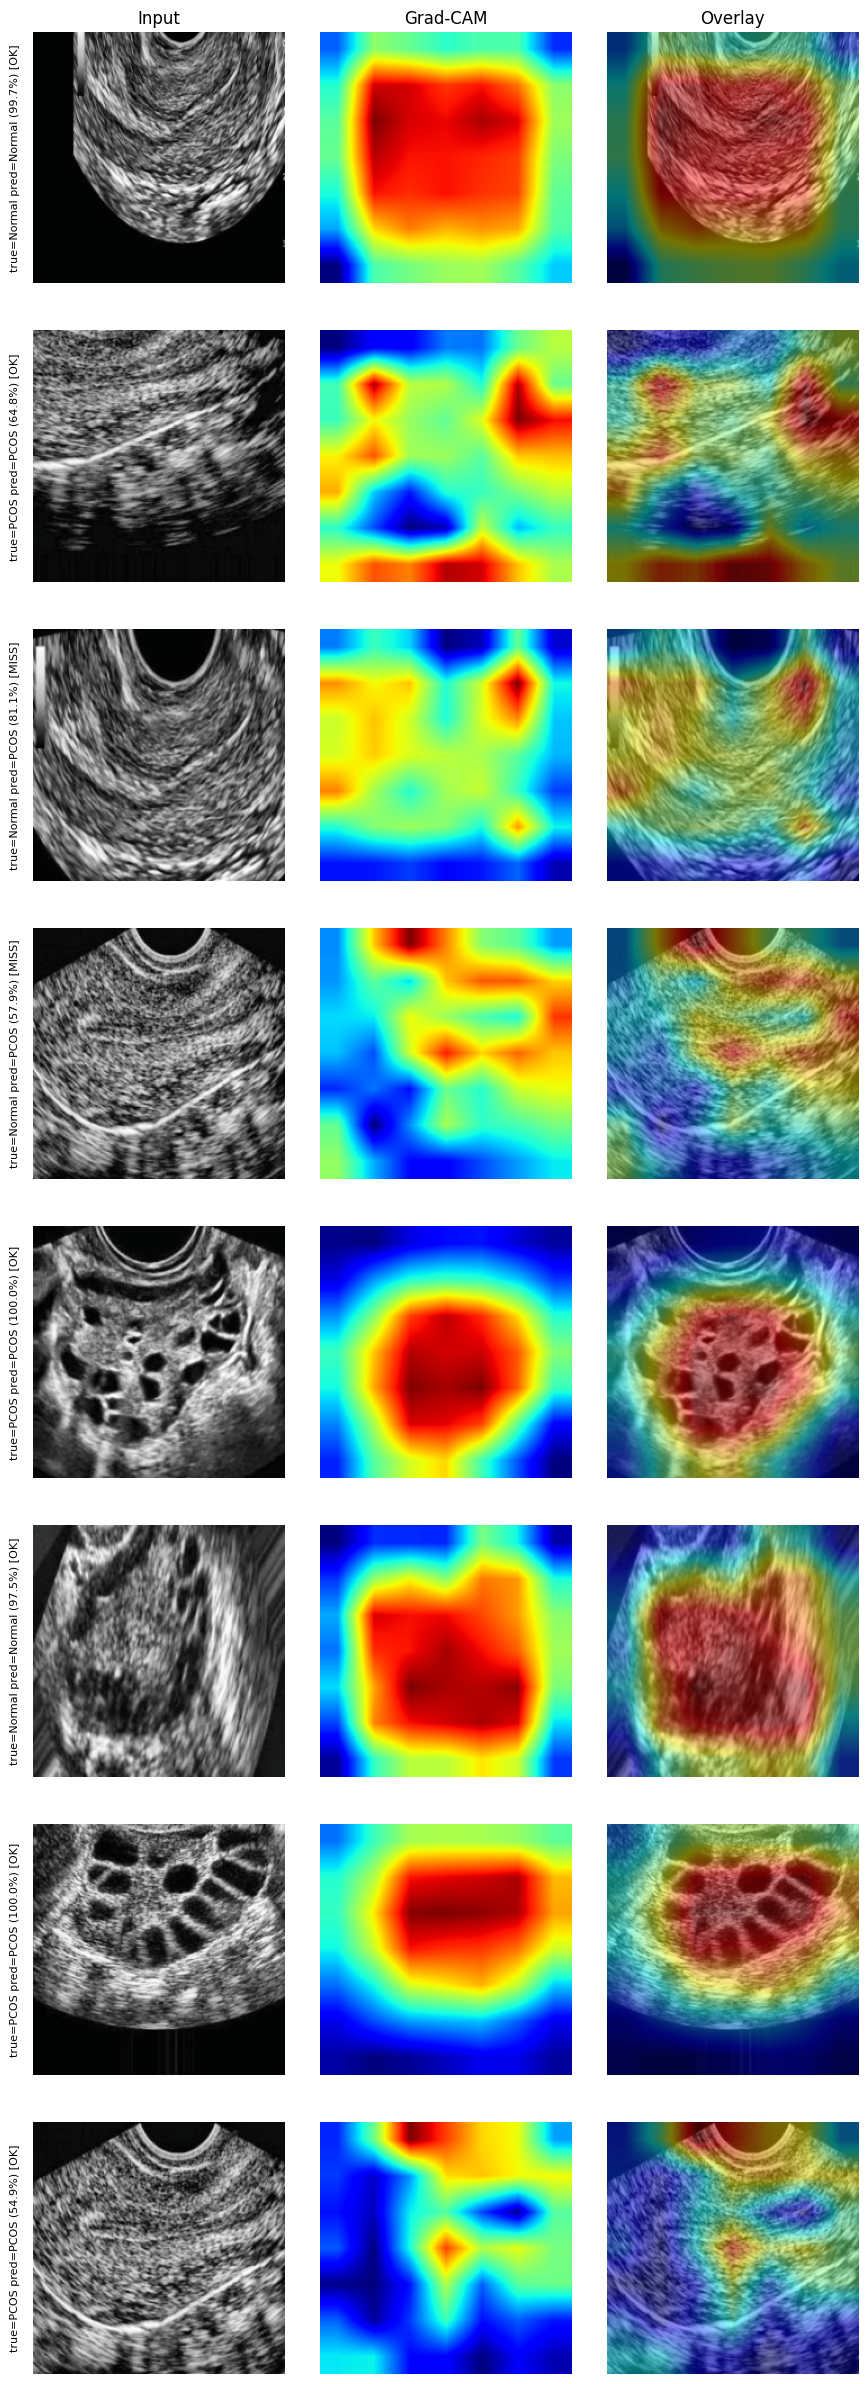

Saved: /kaggle/working/gradcam_repformer_pcos.png


In [16]:
def unnormalize(img_tensor):
    mean = np.array(IMAGENET_MEAN).reshape(3, 1, 1)
    std = np.array(IMAGENET_STD).reshape(3, 1, 1)
    img = img_tensor.cpu().numpy() * std + mean
    return np.clip(img.transpose(1, 2, 0), 0, 1)

def overlay_heatmap(rgb_img, cam, alpha=0.45):
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    return np.clip(alpha * heatmap + (1 - alpha) * rgb_img, 0, 1)

N_SAMPLES = 8
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test), size=min(N_SAMPLES, len(test)), replace=False)

fig, axes = plt.subplots(len(sample_idx), 3, figsize=(9, 3 * len(sample_idx)))
if len(sample_idx) == 1:
    axes = axes[None, :]

for row, idx in enumerate(sample_idx):
    path, true_label, source = test[idx]
    img = load_and_preprocess(path)
    tensor = eval_transform(image=img)["image"].unsqueeze(0).to(DEVICE)

    cam, pred_class, confidence = gradcam.generate(tensor, class_idx=None)
    rgb = unnormalize(tensor[0])
    overlay = overlay_heatmap(rgb, cam)

    correct = "OK" if pred_class == true_label else "MISS"
    title = (f"true={CLASS_NAMES[true_label]} pred={CLASS_NAMES[pred_class]} "
             f"({confidence*100:.1f}%) [{correct}]")

    axes[row, 0].imshow(rgb);      axes[row, 0].set_title("Input" if row == 0 else "")
    axes[row, 1].imshow(cam, cmap="jet"); axes[row, 1].set_title("Grad-CAM" if row == 0 else "")
    axes[row, 2].imshow(overlay);  axes[row, 2].set_title("Overlay" if row == 0 else "")
    for ax in axes[row]:
        ax.axis("off")
    axes[row, 0].text(-0.05, 0.5, title, transform=axes[row, 0].transAxes,
                       fontsize=8, va="center", ha="right", rotation=90)

plt.tight_layout()
out_path = os.path.join(WORK_DIR, "gradcam_repformer_pcos.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

gradcam.remove_hooks()

### Cross-attention gate weights (extra interpretability)

In [17]:
# Bonus: how much the fusion gate weighted the CNN (RepViT) branch vs.
# the ViT (EfficientViT) branch for each of the sample images above.
model_repformer.eval()
print(f"{'true':<8}{'pred':<8}{'w_cnn(RepViT)':>16}{'w_vit(EfficientViT)':>22}")
with torch.no_grad():
    for idx in sample_idx:
        path, true_label, source = test[idx]
        img = load_and_preprocess(path)
        tensor = eval_transform(image=img)["image"].unsqueeze(0).to(DEVICE)
        logits, pooled, gate_weights = model_repformer(tensor, return_features=True)
        pred = int(logits.argmax(dim=1).item())
        w_cnn, w_vit = gate_weights[0].mean(dim=0).cpu().numpy() if gate_weights.dim() == 3 else gate_weights[0].cpu().numpy()
        print(f"{CLASS_NAMES[true_label]:<8}{CLASS_NAMES[pred]:<8}{w_cnn:>16.3f}{w_vit:>22.3f}")

true    pred       w_cnn(RepViT)   w_vit(EfficientViT)
Normal  Normal             0.716                 0.284
PCOS    PCOS               0.087                 0.913
Normal  PCOS               0.094                 0.906
Normal  PCOS               0.110                 0.890
PCOS    PCOS               0.237                 0.763
Normal  Normal             0.360                 0.640
PCOS    PCOS               0.208                 0.792
PCOS    PCOS               0.123                 0.877


## ROC & Precision-Recall curves (RepFormer-PCOS only)
Uses `y_true_repformer` / `y_prob_repformer` already computed above. For the multi-model overlay (all 9 models on one ROC plot), use notebook 10, which needs every model's saved `.npz` results.

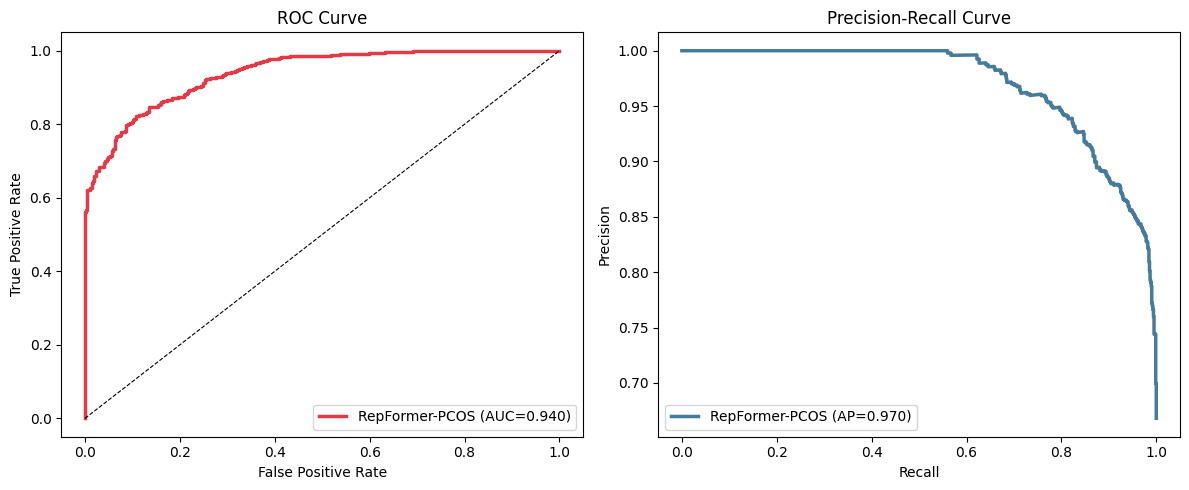

ROC-AUC: 0.9395 | Average Precision: 0.9704
Saved: /kaggle/working/roc_pr_repformer_pcos.png


In [18]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(y_true_repformer, y_prob_repformer)
roc_auc = auc(fpr, tpr)
prec_c, rec_c, _ = precision_recall_curve(y_true_repformer, y_prob_repformer)
ap = average_precision_score(y_true_repformer, y_prob_repformer)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, color="#e63946", linewidth=2.5, label=f"RepFormer-PCOS (AUC={roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend(loc="lower right")

axes[1].plot(rec_c, prec_c, color="#457b9d", linewidth=2.5, label=f"RepFormer-PCOS (AP={ap:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(loc="lower left")

plt.tight_layout()
out_path = os.path.join(WORK_DIR, "roc_pr_repformer_pcos.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"ROC-AUC: {roc_auc:.4f} | Average Precision: {ap:.4f}")
print("Saved:", out_path)